## Task 1: EDA on Superstore Retail Sales
Exploratory data analysis of Superstore sales data: data cleaning, monthly seasonality, category and region performance, discount sensitivity and customer purchase volume.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Data/superstore_sales.csv', encoding='latin-1')
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


## 2. Data Profiling (Missing Values)

In [3]:
print (df.shape)
print(df.isnull().sum())
df.info()

(10800, 21)
Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-

In [4]:
blank = df[df['Order Date'].isnull()]
print('Rows with no Order Date:', blank.shape[0])
blank.head(10)

Rows with no Order Date: 806


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9994,Person,Region,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,Chuck Magee,East,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9998,Cassandra Brandow,South,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9999,Returned,Order ID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10001,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10002,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10003,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
pc = df[df['Postal Code'].isnull() & df['Order Date'].notnull()]
pc[['Order ID', 'City', 'State', 'Postal Code']]

,Order ID,City,State,Postal Code
2234,CA-2018-104066,Burlington,Vermont,NaN
5274,CA-2016-162887,Burlington,Vermont,NaN
8798,US-2017-150140,Burlington,Vermont,NaN
9146,US-2017-165505,Burlington,Vermont,NaN
9147,US-2017-165505,Burlington,Vermont,NaN
9148,US-2017-165505,Burlington,Vermont,NaN
9386,US-2018-127292,Burlington,Vermont,NaN
9387,US-2018-127292,Burlington,Vermont,NaN
9388,US-2018-127292,Burlington,Vermont,NaN
9389,US-2018-127292,Burlington,Vermont,NaN


## 3. Data Cleaning and Date Parsing
The CSV contained two extra tables at the bottom (People and Returns, 806 rows). These were removed, leaving 9,994 0rders. Dates were parsed in month/day/year format,Year and Year-Month columns were created, and 11 missing Postal Codes (Burlington, Vermont) were filled with 05401.

In [6]:
df = df[df['Order Date'].notna()].copy()
print('Rows after cleaning:', df.shape[0])
df['Row ID'] = df['Row ID'].astype(int)
df['Order Date'] = pd.to_datetime(df['Order Date'], format= '%m/%d/%Y')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%m/%d/%Y')
print('Ship Date before Order Date:', (df['Ship Date'] < df['Order Date']).sum())
print(df['Order Date'].min(), 'to', df['Order Date'].max())
df['Year'] = df['Order Date'].dt.year
df['Year-Month'] = df['Order Date'].dt.to_period('M').astype(str)
print(df[df['Postal Code'].isnull()][['Order ID', 'City','State']])

Rows after cleaning: 9994
Ship Date before Order Date: 0
2015-01-03 00:00:00 to 2018-12-30 00:00:00
            Order ID        City    State
2234  CA-2018-104066  Burlington  Vermont
5274  CA-2016-162887  Burlington  Vermont
8798  US-2017-150140  Burlington  Vermont
9146  US-2017-165505  Burlington  Vermont
9147  US-2017-165505  Burlington  Vermont
9148  US-2017-165505  Burlington  Vermont
9386  US-2018-127292  Burlington  Vermont
9387  US-2018-127292  Burlington  Vermont
9388  US-2018-127292  Burlington  Vermont
9389  US-2018-127292  Burlington  Vermont
9741  CA-2016-117086  Burlington  Vermont


## 4. Fixing Missing Postal Codes

In [7]:
df['Postal Code'] = df['Postal Code'].fillna(5401).astype(str).str.zfill(5)
print('Missing values left:', df.isnull().sum().sum())

Missing values left: 0


## 5. Sales and Profit by Category, Region, Segment

In [8]:
for col in ['Category', 'Region', 'Segment']:
    print(df.groupby(col)[['Sales', 'Profit']].sum().round(2).sort_values('Sales', ascending=False))
    print()

                     Sales     Profit
Category                             
Technology       836154.03  145454.95
Furniture        741999.80   18451.27
Office Supplies  719047.03  122490.80

             Sales     Profit
Region                       
West     725457.82  108418.45
East     678781.24   91522.78
Central  501239.89   39706.36
South    391721.90   46749.43

                  Sales     Profit
Segment                           
Consumer     1161401.34  134119.21
Corporate     706146.37   91979.13
Home Office   429653.15   60298.68



## 6. Monthly Sales Trend and Seasonality

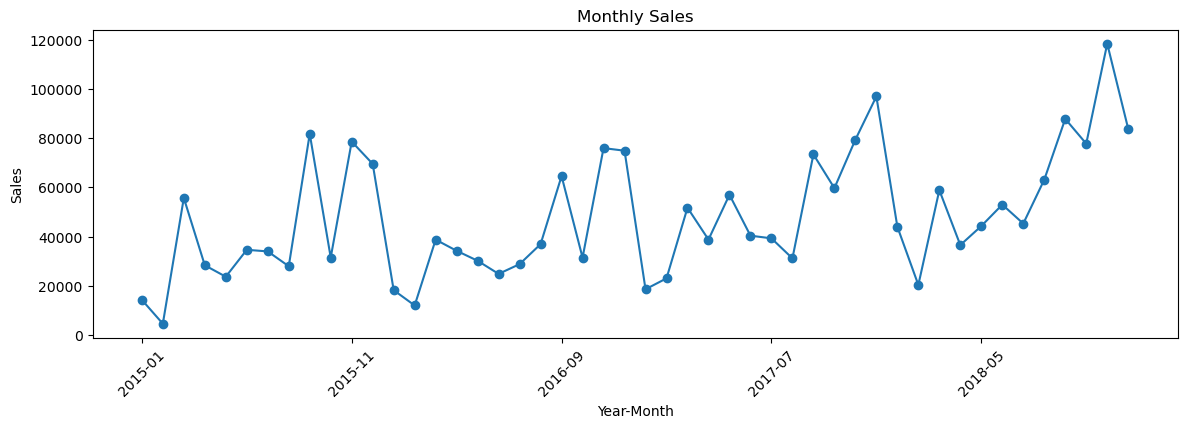

In [9]:
monthly = df.groupby('Year-Month')['Sales'].sum()
monthly.plot(figsize= (14, 4), marker='o', title='Monthly Sales')
plt.xticks(rotation=45)
plt.ylabel('Sales')
plt.show()

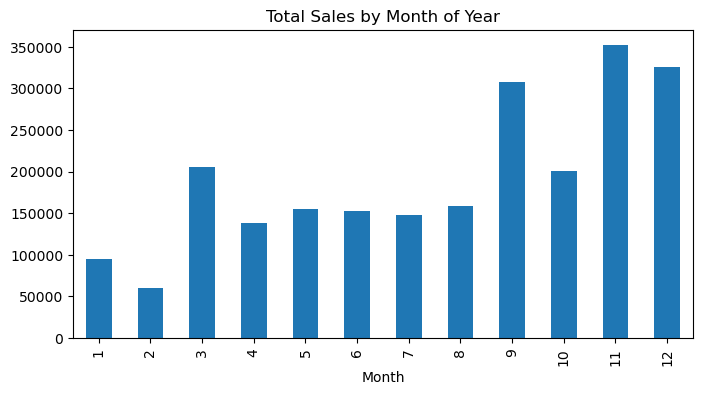

In [10]:
df.groupby(df['Order Date'].dt.month)['Sales'].sum().plot(kind= 'bar', figsize=(8, 4), title='Total Sales by Month of Year')
plt.xlabel('Month')
plt.show()

## 7. Discount Sensitivity

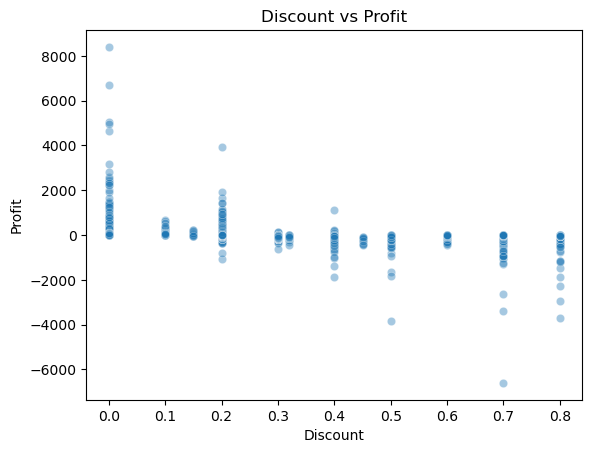

Discount
0.00     66.90
0.10     96.06
0.15     27.29
0.20     24.70
0.30    -45.68
0.32    -88.56
0.40   -111.93
0.45   -226.65
0.50   -310.70
0.60    -43.08
0.70    -95.87
0.80   -101.80
Name: Profit, dtype: float64


In [11]:
sns.scatterplot(data=df, x='Discount', y='Profit', alpha=0.4)
plt.title('Discount vs Profit')
plt.show()
print(df.groupby('Discount')['Profit'].mean().round(2))

## 8. Loss-Making Sub-Categories and States

In [12]:
print(df.groupby('Sub-Category')['Profit'].sum().sort_values().head(5).round(2))
print()
print(df.groupby('State')['Profit'].sum().sort_values().head(5).round(2))

Sub-Category
Tables      -17725.48
Bookcases    -3472.56
Supplies     -1189.10
Fasteners      949.52
Machines      3384.76
Name: Profit, dtype: float64

State
Texas            -25729.36
Ohio             -16971.38
Pennsylvania     -15559.96
Illinois         -12607.89
North Carolina    -7490.91
Name: Profit, dtype: float64


## 9. Customer Purchase Volume

In [13]:
top = df.groupby('Customer Name').agg(Orders=('Order ID', 'nunique'), Sales=('Sales', 'sum'))
top.sort_values('Sales', ascending=False).head(10).round(2)

,Orders,Sales
Customer Name,,
Sean Miller,5,25043.05
Tamara Chand,5,19052.22
Raymond Buch,6,15117.34
Tom Ashbrook,4,14595.62
Adrian Barton,10,14473.57
Ken Lonsdale,12,14175.23
Sanjit Chand,9,14142.33
Hunter Lopez,6,12873.30
Sanjit Engle,11,12209.44


## 10. Business Findings

1. Technology has the highest sales and profit (about 17% margin). Furniture has a margin of only 2.5% because Tables and Bookcases lose money.
2. Sales are highest in September, November and December, and lowest in January and Frebruary. Sales grew from 2015 to 2018.
3. West has the best margin (14.9%). Central has the lowest margin (7.9%) despite sales of 5 lakh.
4. Large profits occur at 0-20% discount. Above 30% discount most orders have Zero or negative profit.
5. Tables (-17.7 thousand) is the biggest loss sub-category. Texas, Ohio, Pennsylvania and Illinois lose the most. The top 10 customers give only about 6.7% of total sales.